### Import libaries


In [60]:
import pandas as pd

In [61]:
path = "~/the-circor-digiscope-phonocardiogram-dataset-1.0.3/training_data.csv"
fh = pd.read_csv(path)
fh.head(4)

,Patient ID,Recording locations:,Age,Sex,Height,Weight,Pregnancy status,Murmur,Murmur locations,Most audible location,...,Systolic murmur pitch,Systolic murmur quality,Diastolic murmur timing,Diastolic murmur shape,Diastolic murmur grading,Diastolic murmur pitch,Diastolic murmur quality,Outcome,Campaign,Additional ID
0,2530,AV+PV+TV+MV,Child,Female,98.0,15.9,False,Absent,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN
1,9979,AV+PV+TV+MV,Child,Female,103.0,13.1,False,Present,AV+MV+PV+TV,TV,...,High,Harsh,NaN,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN
2,9983,AV+PV+TV+MV,Child,Male,115.0,19.1,False,Unknown,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN
3,13918,AV+PV+TV+MV,Child,Male,98.0,15.9,False,Present,TV,TV,...,Low,Blowing,NaN,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN


In [62]:
print(fh.shape)

(942, 23)


In [63]:
print(fh.isnull().sum())

Patient ID                    0
Recording locations:          0
Age                          74
Sex                           0
Height                      116
Weight                      105
Pregnancy status              0
Murmur                        0
Murmur locations            763
Most audible location       763
Systolic murmur timing      764
Systolic murmur shape       764
Systolic murmur grading     764
Systolic murmur pitch       764
Systolic murmur quality     764
Diastolic murmur timing     937
Diastolic murmur shape      937
Diastolic murmur grading    937
Diastolic murmur pitch      937
Diastolic murmur quality    937
Outcome                       0
Campaign                      0
Additional ID               802
dtype: int64


In [64]:
columnsToDrop = ["Murmur locations", "Most audible location", "Systolic murmur timing",
                 "Systolic murmur shape", "Systolic murmur grading", "Systolic murmur pitch", 
                 "Systolic murmur quality", "Diastolic murmur timing", "Diastolic murmur shape", 
                 "Diastolic murmur grading", "Diastolic murmur pitch", "Diastolic murmur quality",
                 "Additional ID", "Outcome", "Campaign"]

fh = fh.drop(columns=columnsToDrop)

In [65]:
fh.dtypes

Patient ID                int64
Recording locations:        str
Age                         str
Sex                         str
Height                  float64
Weight                  float64
Pregnancy status           bool
Murmur                      str
dtype: object

In [66]:
fh.columns = fh.columns.str.lower().str.replace(" ", "_")

In [67]:
fh.rename(columns={"recording_locations:": "recording_locations"}, inplace=True)

In [68]:
for col in fh.columns:
    print(f"{col}: {fh[col].nunique()}")

patient_id: 942
recording_locations: 28
age: 4
sex: 2
height: 132
weight: 435
pregnancy_status: 2
murmur: 3


In [69]:
fh.dropna(axis= 0, how= 'any', inplace= True)

In [70]:
fh.isnull().sum()

patient_id             0
recording_locations    0
age                    0
sex                    0
height                 0
weight                 0
pregnancy_status       0
murmur                 0
dtype: int64

In [71]:
fh= fh[fh["murmur"] != "Unknown"] # drop rows where murmur is neither present nor absent

In [72]:
fh.shape

(759, 8)

In [74]:
fh.to_csv("clean_data.csv", index=False)

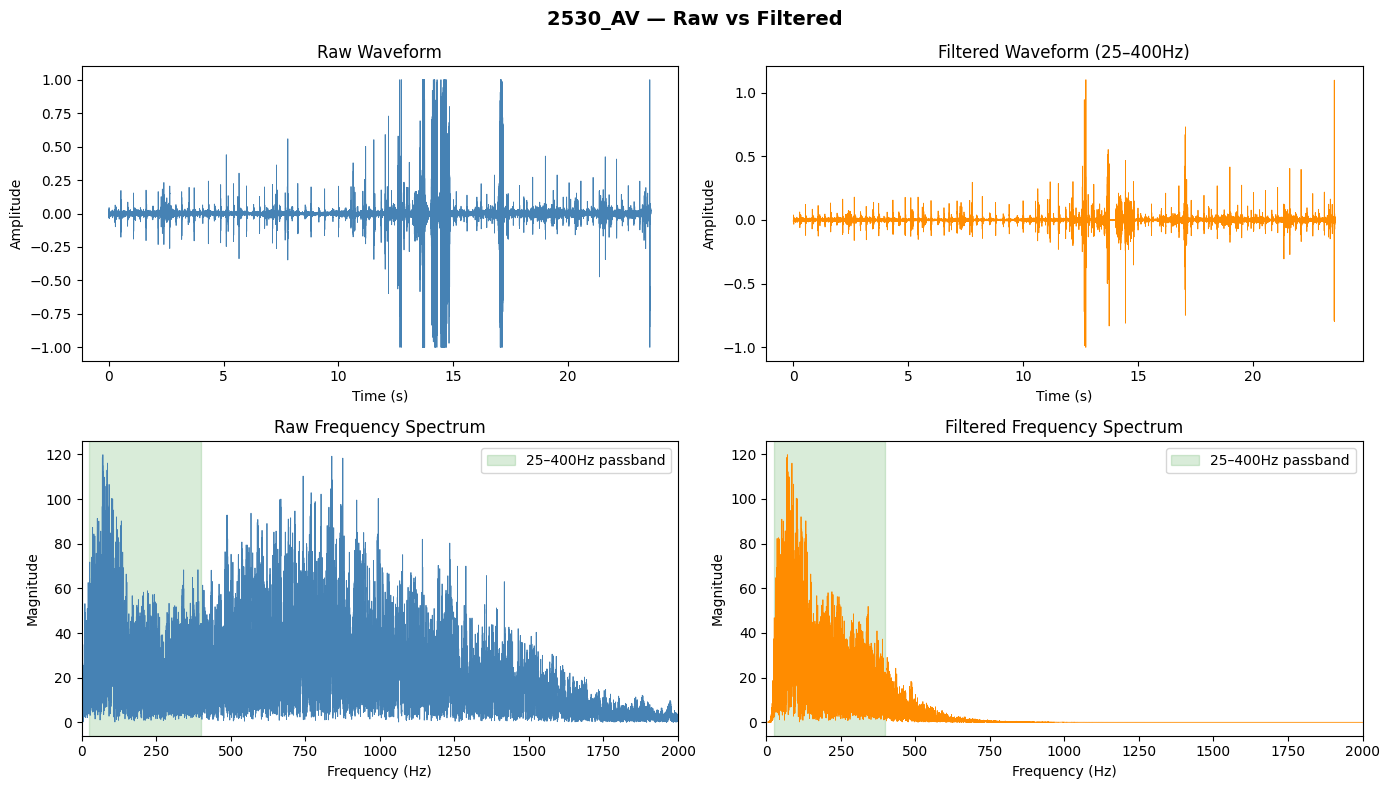

In [1]:
import librosa
import os
import scipy.signal
import matplotlib.pyplot as plt
import numpy as np

path = os.path.expanduser(
    "~/the-circor-digiscope-phonocardiogram-dataset-1.0.3/training_data/2530_AV.wav"
)
numArray, sampleRate = librosa.load(path, sr=None)


def ButterBandpass(low, high, fs, order=3):
    sos = scipy.signal.butter(order, [low, high], btype='bandpass', fs=fs, output='sos')
    return sos


def ApplyBandpass(data, low, high, fs, order=3):
    sos = ButterBandpass(low, high, fs, order)
    filtered = scipy.signal.sosfiltfilt(sos, data)
    return filtered


filteredAudio = ApplyBandpass(numArray, 25, 400, sampleRate)

# Time axis in seconds
time = np.linspace(0, len(numArray) / sampleRate, len(numArray))

# Frequency axis for FFT plots
freqs = np.fft.rfftfreq(len(numArray), d=1/sampleRate)
fft_raw = np.abs(np.fft.rfft(numArray))
fft_filtered = np.abs(np.fft.rfft(filteredAudio))

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle("2530_AV — Raw vs Filtered", fontsize=14, fontweight='bold')

# Top left — raw waveform
axes[0, 0].plot(time, numArray, color='steelblue', linewidth=0.6)
axes[0, 0].set_title("Raw Waveform")
axes[0, 0].set_xlabel("Time (s)")
axes[0, 0].set_ylabel("Amplitude")

# Top right — filtered waveform
axes[0, 1].plot(time, filteredAudio, color='darkorange', linewidth=0.6)
axes[0, 1].set_title("Filtered Waveform (25–400Hz)")
axes[0, 1].set_xlabel("Time (s)")
axes[0, 1].set_ylabel("Amplitude")

# Bottom left — raw frequency spectrum
axes[1, 0].plot(freqs, fft_raw, color='steelblue', linewidth=0.6)
axes[1, 0].set_title("Raw Frequency Spectrum")
axes[1, 0].set_xlabel("Frequency (Hz)")
axes[1, 0].set_ylabel("Magnitude")
axes[1, 0].set_xlim(0, 2000)
axes[1, 0].axvspan(25, 400, alpha=0.15, color='green', label='25–400Hz passband')
axes[1, 0].legend()

# Bottom right — filtered frequency spectrum
axes[1, 1].plot(freqs, fft_filtered, color='darkorange', linewidth=0.6)
axes[1, 1].set_title("Filtered Frequency Spectrum")
axes[1, 1].set_xlabel("Frequency (Hz)")
axes[1, 1].set_ylabel("Magnitude")
axes[1, 1].set_xlim(0, 2000)
axes[1, 1].axvspan(25, 400, alpha=0.15, color='green', label='25–400Hz passband')
axes[1, 1].legend()

plt.tight_layout()
plt.show()